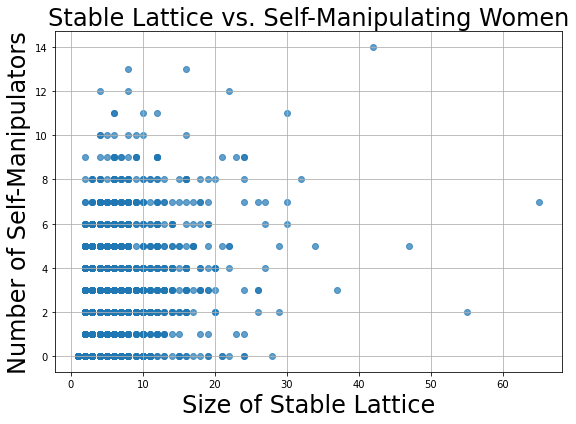

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('mallows_accomplice.csv')

# Extract columns
x = df['number_of_stable_matchings']
y = df['count_self_manipulating_women']

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.xlabel('Size of Stable Lattice', fontsize=24)
plt.ylabel('Number of Self-Manipulators', fontsize=24)
plt.title('Stable Lattice vs. Self-Manipulating Women', fontsize=24)
plt.grid(True)
plt.tight_layout()

# Save as PDF (specify path or filename)
plt.savefig('Mallows_lattice_vs_self.pdf')

plt.show()


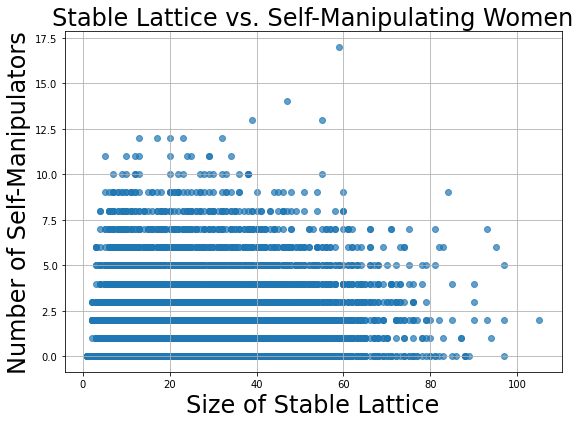

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('mallows_MD_accomplice.csv')

# Extract columns
x = df['number_of_stable_matchings']
y = df['self_manipulating_women']

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.xlabel('Size of Stable Lattice', fontsize=24)
plt.ylabel('Number of Self-Manipulators', fontsize=24)
plt.title('Stable Lattice vs. Self-Manipulating Women', fontsize=24)
plt.grid(True)
plt.tight_layout()

# Save as PDF (specify path or filename)
plt.savefig('MD_Mallows_lattice_vs_self.pdf')

plt.show()


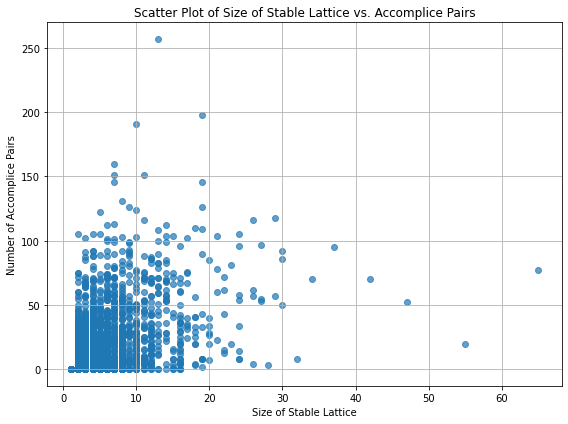

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('mallows_accomplice.csv')

# Extract columns
x = df['number_of_stable_matchings']
y = df['cnt_pairs']

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.xlabel('Size of Stable Lattice')
plt.ylabel('Number of Accomplice Pairs')
plt.title('Scatter Plot of Size of Stable Lattice vs. Accomplice Pairs')
plt.grid(True)
plt.tight_layout()

# Save as PDF (specify path or filename)
#plt.savefig('stable_lattice_vs_accomplice_women.pdf')

plt.show()


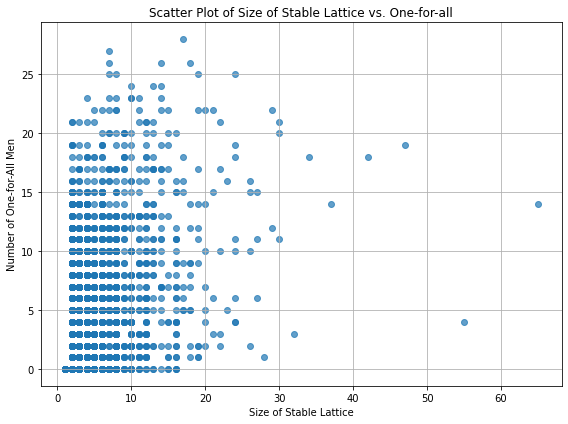

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('mallows_accomplice.csv')

# Extract columns
x = df['number_of_stable_matchings']
y = df['count_men']

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.xlabel('Size of Stable Lattice')
plt.ylabel('Number of One-for-All Men')
plt.title('Scatter Plot of Size of Stable Lattice vs. One-for-all')
plt.grid(True)
plt.tight_layout()

# Save as PDF (specify path or filename)
#plt.savefig('stable_lattice_vs_accomplice_women.pdf')

plt.show()


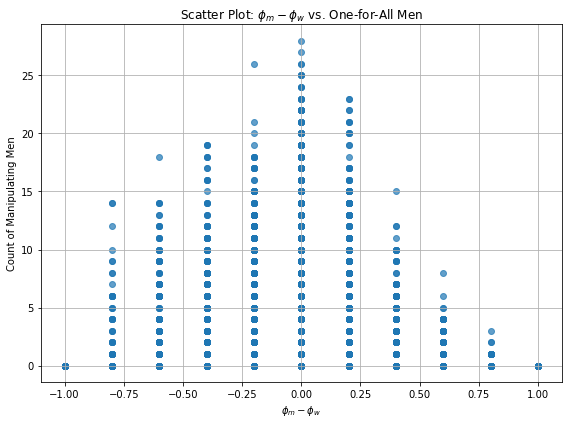

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('mallows_accomplice.csv')

# Compute difference phi_m - phi_w
x = df['phi_m'] - df['phi_w']
y = df['count_men']

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.xlabel('$\phi_m - \phi_w$')
plt.ylabel('Count of Manipulating Men')
plt.title('Scatter Plot: $\phi_m - \phi_w$ vs. One-for-All Men')
plt.grid(True)
plt.tight_layout()
plt.show()


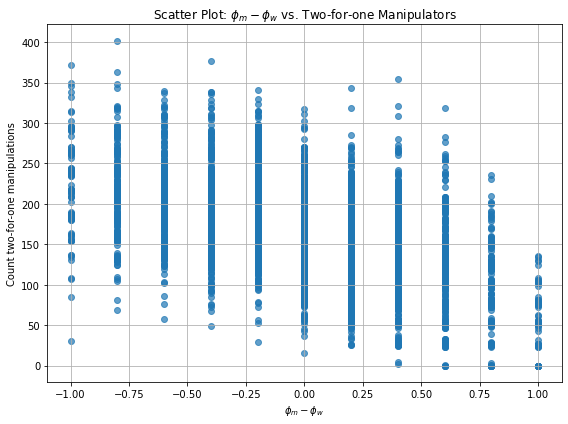

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('two_for_one_results_mallows.csv')

# Compute difference phi_m - phi_w
x = df['Phi1'] - df['Phi2']
y = df['Two_for_one']

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.xlabel('$\phi_m - \phi_w$')
plt.ylabel('Count two-for-one manipulations')
plt.title('Scatter Plot: $\phi_m - \phi_w$ vs. Two-for-one Manipulators')
plt.grid(True)
plt.tight_layout()
plt.show()


In [1]:
import pandas as pd
import statsmodels.api as sm

# Load data
df = pd.read_csv('mallows_accomplice.csv')

# Define independent variables (phi_m and phi_w)
X = df[['phi_m', 'phi_w']]

# Add a constant term for the intercept
X = sm.add_constant(X)

# Define dependent variable
y = df['count_self_manipulating_women']

# Fit the OLS regression model
model = sm.OLS(y, X).fit()

# Print the summary
print(model.summary())


AttributeError: module 'numpy' has no attribute 'MachAr'

In [19]:
!pip install --upgrade numpy scipy


Requirement already up-to-date: numpy in c:\users\shraddha pathak\anaconda3\lib\site-packages (1.24.4)
Requirement already up-to-date: scipy in c:\users\shraddha pathak\anaconda3\lib\site-packages (1.10.1)


In [2]:
pip install pandas statsmodels


Note: you may need to restart the kernel to use updated packages.


'C:\Users\SHRADDHA' is not recognized as an internal or external command,
operable program or batch file.


AttributeError: 'tuple' object has no attribute 'size'

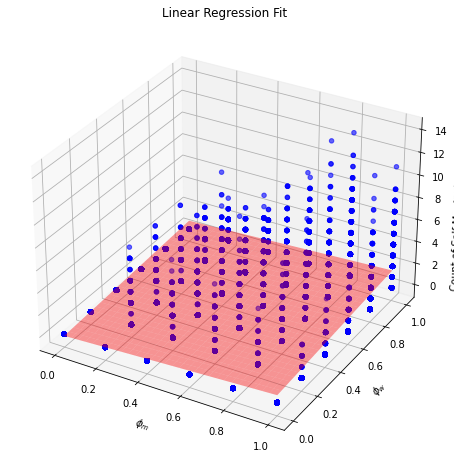

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from mpl_toolkits.mplot3d import Axes3D  # For 3D plotting

# Load data
df = pd.read_csv('mallows_accomplice.csv')

# Prepare data
X = df[['phi_m', 'phi_w']].values
y = df['count_self_manipulating_women'].values

# Fit linear regression model
model = LinearRegression()
model.fit(X, y)

# Create grid to plot regression plane
phi_m_range = np.linspace(df['phi_m'].min(), df['phi_m'].max(), 30)
phi_w_range = np.linspace(df['phi_w'].min(), df['phi_w'].max(), 30)
phi_m_grid, phi_w_grid = np.meshgrid(phi_m_range, phi_w_range)
X_grid = np.c_[phi_m_grid.ravel(), phi_w_grid.ravel()]
y_pred_grid = model.predict(X_grid).reshape(phi_m_grid.shape)

# Plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter actual data points
ax.scatter(df['phi_m'], df['phi_w'], y, color='blue', alpha=0.6, label='Actual')

# Plot regression plane
ax.plot_surface(phi_m_grid, phi_w_grid, y_pred_grid, color='red', alpha=0.4, label='Regression plane')

# Labels
ax.set_xlabel(r'$\phi_m$')
ax.set_ylabel(r'$\phi_w$')
ax.set_zlabel('Count of Self-Manipulating Women')
ax.set_title('Linear Regression Fit')

plt.legend()
plt.show()
